# 04 · Dataset splitting

Assign each speaker to exactly one partition before augmentation or learned transforms.

Run notebooks **01 → 09** in order. This notebook contains its implementation directly; it does not import project code from `src/`.

In [1]:
from pathlib import Path
import json
import hashlib
from collections import Counter
import matplotlib.pyplot as plt
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "configs/preprocessing.json").exists())
cfg = json.loads((root / "configs/preprocessing.json").read_text())
out = root / "data/processed" / cfg["run_name"]
reports = root / "reports/preprocessing" / cfg["run_name"]
out.mkdir(parents=True, exist_ok=True)
reports.mkdir(parents=True, exist_ok=True)

In [2]:
def load_manifest(name):
    path = out / name
    if not path.exists():
        raise FileNotFoundError(f"Run the preceding notebook first: {path}")
    return [json.loads(line) for line in path.read_text().splitlines()]

def save_manifest(name, rows):
    path = out / name
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w") as stream:
        for row in rows:
            stream.write(json.dumps(row, allow_nan=False) + "\n")

def save_json(path, value):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n")

## Deterministic speaker assignment

A hash of the experiment seed and speaker ID produces an order-independent 80/10/10 assignment.

### Math for the next code block — deterministic speaker split

For speaker ID $s$ and experiment seed $k$:

$$u(s)=\frac{\operatorname{int}(\operatorname{SHA256}(k\Vert s)_{0:64})}{2^{64}}\in[0,1).$$

With $a=0.8$ and $b=0.1$:

$$\operatorname{split}(s)=
\begin{cases}
\text{train},&u<a,\\
\text{validation},&a\le u<a+b,\\
\text{test},&u\ge a+b.
\end{cases}$$

All recordings from one speaker share the same $u(s)$ and therefore the same partition.

In [3]:
def speaker_fraction(speaker_id):
    digest = hashlib.sha256(f"{cfg['seed']}:{speaker_id}".encode()).hexdigest()
    return int(digest[:16],16) / 2**64

def choose_split(speaker_id):
    value = speaker_fraction(speaker_id)
    if value < cfg["train_fraction"]: return "train"
    if value < cfg["train_fraction"] + cfg["validation_fraction"]: return "validation"
    return "test"

In [4]:
cleaned = load_manifest("03_cleaned.jsonl")
rows = [{**row,"split":choose_split(row["speaker_id"])} for row in cleaned]
save_manifest("04_split_manifest.jsonl",rows)
for split in ("train","validation","test"):
    save_manifest(f"04_splits/{split}.jsonl",[r for r in rows if r["split"]==split])

In [5]:
summary=[]
for split in ("train","validation","test"):
    selected=[r for r in rows if r["split"]==split]
    summary.append({"split":split,"recordings":len(selected),"speakers":len({r["speaker_id"] for r in selected}),
                    "positive":sum(r["is_keyword"] for r in selected),"negative":sum(not r["is_keyword"] for r in selected)})
display(summary)

[{'split': 'train',
  'recordings': 6357,
  'speakers': 1397,
  'positive': 799,
  'negative': 5558},
 {'split': 'validation',
  'recordings': 797,
  'speakers': 175,
  'positive': 95,
  'negative': 702},
 {'split': 'test',
  'recordings': 819,
  'speakers': 178,
  'positive': 102,
  'negative': 717}]

## Verify separation visually and directly

In [6]:
INK, MUTED, BLUE, TEAL, AMBER, RED = "#152b42", "#586c7d", "#3265bb", "#087f8c", "#ba6b10", "#bf4545"
plt.rcParams.update({"figure.facecolor":"#f4f7fb", "axes.facecolor":"white",
                     "axes.edgecolor":"#c8d5e2", "axes.labelcolor":INK,
                     "xtick.color":MUTED, "ytick.color":MUTED, "font.size":11})

def finish_figure(fig, name):
    directory = reports / "figures"
    directory.mkdir(parents=True, exist_ok=True)
    fig.savefig(directory / f"{name}.png", dpi=170, bbox_inches="tight")
    fig.savefig(directory / f"{name}.svg", bbox_inches="tight")
    plt.show()

### Math for the next code block — disjointness check

For train, validation, and test identifier sets $S_{tr},S_{va},S_{te}$, leakage is absent only if

$$S_{tr}\cap S_{va}=S_{tr}\cap S_{te}=S_{va}\cap S_{te}=\varnothing.$$

The code checks this separately for speaker IDs and exact PCM hashes.

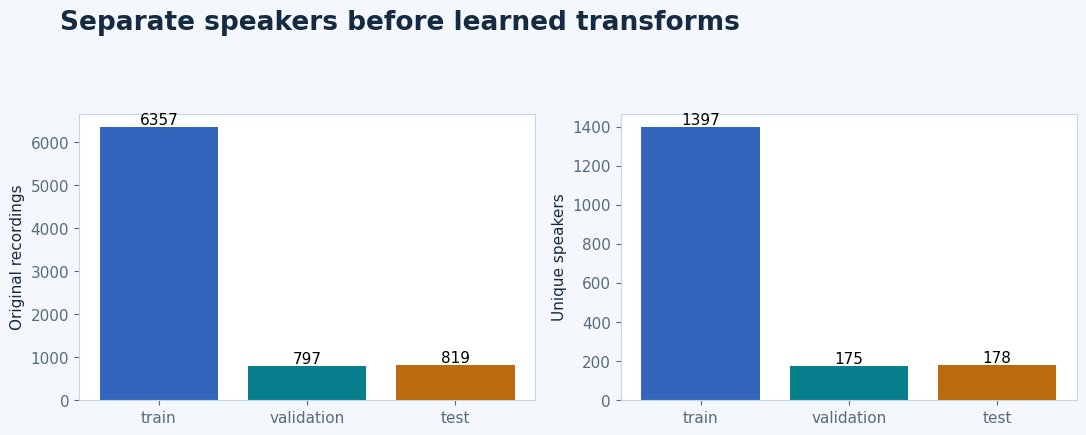

In [7]:
for field in ("speaker_id","pcm_sha256"):
    sets={s:{r[field] for r in rows if r["split"]==s} for s in ("train","validation","test")}
    assert not sets["train"]&sets["validation"] and not sets["train"]&sets["test"] and not sets["validation"]&sets["test"]
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
for ax,key,label in zip(axes,["recordings","speakers"],["Original recordings","Unique speakers"]):
    values=[r[key] for r in summary]; bars=ax.bar([r["split"] for r in summary],values,color=[BLUE,TEAL,AMBER]); ax.bar_label(bars); ax.set(ylabel=label)
fig.suptitle("Separate speakers before learned transforms",x=.06,ha="left",fontsize=19,weight="bold",color=INK)
fig.tight_layout(rect=(0,.02,1,.88)); finish_figure(fig,"04_speaker_splits")

Continue with [05 · Signal standardization](05_signal_standardization.ipynb).